In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from src.features import BASE, DERIVADAS

df = pd.read_csv(RAIZ / "data" / "processed" / "concreto_features.csv")
TODAS = BASE + DERIVADAS

y = df["resistencia"]
grupos = df["id_mezcla"]
print(df.shape, "| mezclas:", grupos.nunique())

(1005, 16) | mezclas: 427


In [2]:
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def evaluar(modelo, columnas, cv, usar_grupos=False):
    """Predicciones fuera de muestra para todas las filas y sus métricas."""
    pred = cross_val_predict(
        modelo, df[columnas], y, cv=cv,
        groups=grupos if usar_grupos else None, n_jobs=-1,
    )
    return {
        "R2": r2_score(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "MAE": mean_absolute_error(y, pred),
    }

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor

abrams = TransformedTargetRegressor(
    regressor=LinearRegression(), func=np.log, inverse_func=np.exp
)
bosque = RandomForestRegressor(n_estimators=300, random_state=42)

esquemas = {
    "Aleatoria": (KFold(n_splits=5, shuffle=True, random_state=42), False),
    "Por grupos": (GroupKFold(n_splits=5), True),
}
modelos = {
    "Abrams + edad": (abrams, ["a_lig", "log_edad"]),
    "Random Forest": (bosque, TODAS),
}

filas = []
for nom_m, (m, cols) in modelos.items():
    for nom_e, (cv, g) in esquemas.items():
        r = evaluar(m, cols, cv, usar_grupos=g)
        filas.append({"modelo": nom_m, "validación": nom_e, **r})

resultados = pd.DataFrame(filas).round(3)
resultados

,modelo,validación,R2,RMSE,MAE
0,Abrams + edad,Aleatoria,0.731,8.450,6.290
1,Abrams + edad,Por grupos,0.732,8.426,6.279
2,Random Forest,Aleatoria,0.920,4.603,3.264
3,Random Forest,Por grupos,0.882,5.589,3.824


In [4]:
clave = ["cemento", "escoria", "ceniza", "agua", "superplast",
         "agr_grueso", "agr_fino", "edad"]

n = df.groupby(clave)["resistencia"].transform("size")
rep = df[n >= 2]

ss = rep.groupby(clave)["resistencia"].apply(lambda s: ((s - s.mean())**2).sum()).sum()
gl = (rep.groupby(clave).size() - 1).sum()

print("Filas con réplica:", len(rep))
print("Grupos con réplica:", rep.groupby(clave).ngroups)
print(f"Desviación típica entre réplicas: {np.sqrt(ss / gl):.2f} MPa")

Filas con réplica: 22
Grupos con réplica: 9
Desviación típica entre réplicas: 8.14 MPa


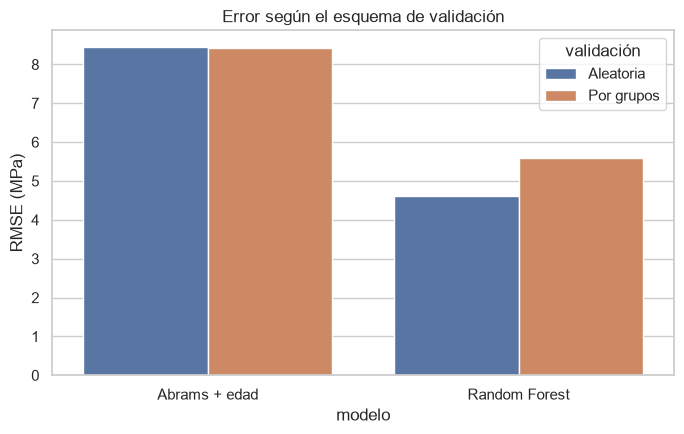

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

resultados.to_csv(RAIZ / "reports" / "resultados_validacion.csv", index=False)

plt.figure(figsize=(7, 4.5))
sns.barplot(data=resultados, x="modelo", y="RMSE", hue="validación")
plt.ylabel("RMSE (MPa)")
plt.title("Error según el esquema de validación")
plt.tight_layout()
plt.savefig(FIG / "06_validacion_rmse.png", dpi=150)
plt.show()

## Conclusiones de la validación

- Con validación aleatoria, el Random Forest alcanza R²=0.920 (RMSE 4.60 MPa); con validación por grupos de mezcla, R²=0.882 (RMSE 5.59 MPa). La brecha cuantifica la fuga de información entre edades de una misma mezcla.
- La línea base Abrams + ln(edad) obtiene R²≈0.73 (RMSE ≈8.4 MPa) con ambos esquemas, como se espera de un modelo de dos variables.
- El Random Forest reduce el RMSE un 34% frente a la línea base con validación por grupos.
- Limitación: el agrupamiento es por coincidencia exacta de componentes; mezclas casi idénticas quedan en grupos distintos, por lo que el resultado sigue siendo algo optimista.